# Multi-Seed CI Bars Figure (CIC-IDS2017)

Generates Figure `multiseed_ci_bars` for the new
*Multi-Seed Validation on CIC-IDS2017* subsection of the paper.

**Input layout.** The notebook expects the per-seed summary JSONs produced by the
multi-seed runner, laid out as

```
multiseed_runs/
    cic_ids2017_V1/
        random_forest_summary.json
        tabpfn_summary.json
        tabpfn_2.5_summary.json
        tabicl_summary.json
        tabstar_summary.json
    cic_ids2017_V2/
        ...
    cic_ids2017_V3/
        ...   (no tabstar_summary.json — not run multi-seed on V3)
```

Each `*_summary.json` carries `accuracy_mean`, `accuracy_lo95`, `accuracy_hi95`,
`macro_f1_mean`, `macro_f1_lo95`, `macro_f1_hi95` over five seeds.

**Output.** A two-panel figure (accuracy on the left, macro-F1 on the right) with
five-seed bootstrap 95% CIs as whiskers, saved to both PDF (for the paper) and
PNG (for quick inspection).


In [1]:
# Standard imports.
from pathlib import Path
import json

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Matplotlib styling — kept close to the rest of the paper's figures
# (serif font, small labels, no chartjunk).
mpl.rcParams.update({
    "font.size": 9,
    "font.family": "serif",
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})


In [2]:
# Configuration: data location, variants to plot, model order and colours.
ROOT = Path("multiseed_runs")          # adjust if the data lives elsewhere
OUT_PDF = Path("multiseed_ci_bars.pdf")
OUT_PNG = Path("multiseed_ci_bars.png")

VARIANTS = [
    ("cic_ids2017_V1", "V1"),
    ("cic_ids2017_V2", "V2"),
    ("cic_ids2017_V3", "V3"),
]

# (folder_id, legend label, bar colour). Order = bar order within each variant.
MODELS = [
    ("random_forest", "Random Forest", "#888888"),
    ("tabpfn",        "TabPFN",         "#1f77b4"),
    ("tabpfn_2.5",    "TabPFN 2.5",     "#ff7f0e"),
    ("tabicl",        "TabICL",         "#2ca02c"),
    ("tabstar",       "TabSTAR",        "#d62728"),
]


In [3]:
def load_summary(variant_dir: str, model_id: str) -> dict | None:
    """Load the per-model summary JSON for a given variant, or None if missing.

    A missing file is not an error — it just means that combination was not
    multi-seed under the available compute budget (e.g. TabSTAR on V3).
    """
    fp = ROOT / variant_dir / f"{model_id}_summary.json"
    if not fp.exists():
        return None
    with fp.open() as f:
        return json.load(f)


def collect_metric(metric: str):
    """Pull (means, lo_err, hi_err) arrays of shape [n_models, n_variants].

    metric is one of: 'accuracy', 'macro_f1'. Missing cells are returned as NaN
    so that the plotting code skips them cleanly.
    """
    n_models, n_variants = len(MODELS), len(VARIANTS)
    means = np.full((n_models, n_variants), np.nan)
    lo_err = np.zeros((n_models, n_variants))
    hi_err = np.zeros((n_models, n_variants))
    for i, (mid, _, _) in enumerate(MODELS):
        for j, (vdir, _) in enumerate(VARIANTS):
            s = load_summary(vdir, mid)
            if s is None:
                continue
            m  = s[f"{metric}_mean"]
            lo = s[f"{metric}_lo95"]
            hi = s[f"{metric}_hi95"]
            means[i, j]  = m
            lo_err[i, j] = m  - lo   # matplotlib expects positive error magnitudes
            hi_err[i, j] = hi - m
    return means, lo_err, hi_err


In [4]:
def draw_panel(ax, metric: str, ylabel: str, title: str, ylim: tuple[float, float]):
    """Draw one panel (accuracy or macro-F1) onto the supplied Axes."""
    means, lo_err, hi_err = collect_metric(metric)
    n_models = len(MODELS)
    bar_w = 0.16
    x = np.arange(len(VARIANTS))
    # Centre the group of bars around each variant tick.
    offsets = (np.arange(n_models) - (n_models - 1) / 2) * bar_w

    for i, (mid, mname, mcol) in enumerate(MODELS):
        xpos = x + offsets[i]
        # NaN bars are silently skipped by matplotlib.
        ax.bar(xpos, means[i], bar_w, color=mcol, label=mname,
               edgecolor="black", linewidth=0.4)
        ax.errorbar(xpos, means[i], yerr=[lo_err[i], hi_err[i]],
                    fmt="none", ecolor="black",
                    capsize=2.5, capthick=0.7, lw=0.7)

    ax.set_xticks(x)
    ax.set_xticklabels([n for _, n in VARIANTS])
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.25, linewidth=0.5)


Saved multiseed_ci_bars.pdf and multiseed_ci_bars.png


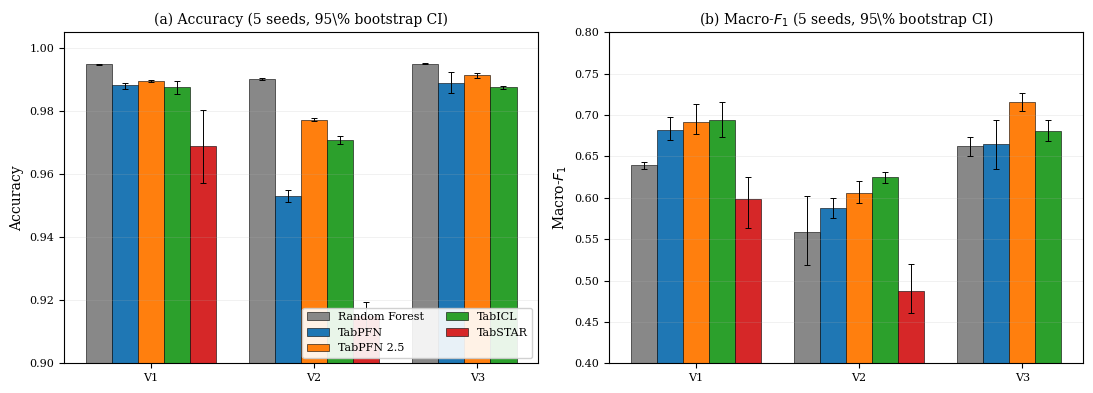

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))

draw_panel(
    axes[0],
    metric="accuracy",
    ylabel="Accuracy",
    title=r"(a) Accuracy (5 seeds, 95\% bootstrap CI)",
    ylim=(0.90, 1.005),
)
# Legend only on the accuracy panel — it would duplicate on the right panel.
axes[0].legend(loc="lower right", ncol=2, frameon=True, framealpha=0.9)

draw_panel(
    axes[1],
    metric="macro_f1",
    ylabel=r"Macro-$F_1$",
    title=r"(b) Macro-$F_1$ (5 seeds, 95\% bootstrap CI)",
    ylim=(0.40, 0.80),
)

plt.tight_layout()
fig.savefig(OUT_PDF, bbox_inches="tight")
fig.savefig(OUT_PNG, bbox_inches="tight", dpi=200)
print(f"Saved {OUT_PDF} and {OUT_PNG}")
plt.show()


## Reading the figure

* **Left panel (accuracy).** Random Forest is the per-cell winner on V1, V2, V3.
  All four foundation models lie below RF; the gap is largest for TabSTAR on V2
  (7.5pp) and smallest for TabPFN 2.5 on V3 (0.4pp). All four
  foundation-vs-RF accuracy gaps are Bonferroni-significant on every variant.
* **Right panel (macro-F1).** The ordering inverts: TabICL leads on V1 and V2,
  TabPFN 2.5 leads on V3, and on V1 all three prior-fitted foundation models are
  Bonferroni-significantly above RF. TabSTAR sits below RF on macro-F1 on V1 and
  V2 — its rare-class recall comes at a precision cost that pulls the macro
  average down.
* **Missing bar.** TabSTAR on V3 was not run multi-seed under the available
  compute budget, hence the absent red bar in the V3 cluster.


## Per-class TabPFN 2.5 vs TabPFN delta table

Generates Table `multiseed_tabpfn_perclass_full` in the paper: per-class
F1 difference (TabPFN 2.5 − TabPFN) across the three multi-seed
CIC-IDS2017 variants, with a significance flag for classes whose 95 %
bootstrap CIs are disjoint between the two models.

**Significance criterion.** A class is flagged $\bigstar$ if the TabPFN
2.5 lower CI exceeds the TabPFN upper CI (TabPFN 2.5 strictly above), or
$\blacktriangledown$ in the opposite direction. This is a *conservative*
test compared with the paired bootstrap used for the LLM panel
(Table 4 of the paper), since it ignores the variance reduction
available from within-seed pairing. The pipeline writes per-seed
*aggregate* metrics (accuracy, macro-F1) to `*_per_seed.csv` and
per-class metrics only as bootstrap CIs in `*_summary.json`; the
per-seed per-class F1 values required for paired bootstrap are not
persisted. If a future pipeline run adds per-seed per-class output,
the bottom of this section sketches the swap-in for a paired test.

In [6]:
# Class taxonomies for CIC-IDS2017.
# Fine = native 15-class label set; V1 and V2 use this.
# Grouped = 9-class super-class taxonomy; V3 uses this.
FINE_ORDER = [
    "BENIGN", "Bot", "DDoS",
    "DoS GoldenEye", "DoS Hulk", "DoS Slowhttptest", "DoS slowloris",
    "FTP-Patator", "SSH-Patator",
    "Heartbleed", "Infiltration", "PortScan",
    "Web Attack  Brute Force",
    "Web Attack  Sql Injection",
    "Web Attack  XSS",
]
GROUPED_ORDER = [
    "BENIGN", "Bot", "Brute Force", "DDoS", "DoS",
    "Heartbleed", "Infiltration", "Port Scan", "Web Attack",
]
# Display names — collapse the double whitespace that appears in some CIC-IDS2017
# label spellings (artefact of the dataset's raw column).
PRETTY = {
    "Web Attack  Brute Force":   "Web Attack Brute Force",
    "Web Attack  Sql Injection": "Web Attack SQL Injection",
    "Web Attack  XSS":            "Web Attack XSS",
}


In [7]:
import pandas as pd


def perclass_delta(pfn_summary, pfn25_summary, classes):
    """Return a DataFrame with one row per class.

    Columns:
        delta  - TabPFN 2.5 F1 mean minus TabPFN F1 mean
        sig    - '+' (TabPFN 2.5 strictly above, disjoint CIs),
                 '-' (TabPFN strictly above, disjoint CIs),
                 ''  (CIs overlap)
        pfn_f1, pfn25_f1 - the two raw F1 means, useful for sanity-checking
    """
    rows = []
    for cls in classes:
        a = pfn_summary["per_class_f1"].get(cls)
        b = pfn25_summary["per_class_f1"].get(cls)
        if a is None or b is None:
            rows.append({"class": cls, "delta": None, "sig": "",
                         "pfn_f1": None, "pfn25_f1": None})
            continue
        delta = b["f1_mean"] - a["f1_mean"]
        if b["f1_lo95"] > a["f1_hi95"]:
            sig = "+"
        elif a["f1_lo95"] > b["f1_hi95"]:
            sig = "-"
        else:
            sig = ""
        rows.append({
            "class": PRETTY.get(cls, cls),
            "delta": round(delta, 4),
            "sig": sig,
            "pfn_f1": round(a["f1_mean"], 4),
            "pfn25_f1": round(b["f1_mean"], 4),
        })
    return pd.DataFrame(rows)


# Fine taxonomy: V1, V2.
df_v1 = perclass_delta(
    load_summary("cic_ids2017_V1", "tabpfn"),
    load_summary("cic_ids2017_V1", "tabpfn_2.5"),
    FINE_ORDER,
)
df_v2 = perclass_delta(
    load_summary("cic_ids2017_V2", "tabpfn"),
    load_summary("cic_ids2017_V2", "tabpfn_2.5"),
    FINE_ORDER,
)
# Grouped taxonomy: V3.
df_v3 = perclass_delta(
    load_summary("cic_ids2017_V3", "tabpfn"),
    load_summary("cic_ids2017_V3", "tabpfn_2.5"),
    GROUPED_ORDER,
)

# Combined fine view (V1 / V2 side by side).
fine = df_v1[["class", "delta", "sig"]].rename(columns={"delta": "V1_delta", "sig": "V1_sig"})
fine["V2_delta"] = df_v2["delta"].values
fine["V2_sig"]   = df_v2["sig"].values

print("--- Fine taxonomy (V1, V2) ---")
print(fine.to_string(index=False))
print()
print("--- Grouped taxonomy (V3) ---")
print(df_v3[["class", "delta", "sig"]].to_string(index=False))
print()

# Win / loss / tie counts per variant.
for label, df in [("V1", df_v1), ("V2", df_v2), ("V3", df_v3)]:
    w = (df["sig"] == "+").sum()
    l = (df["sig"] == "-").sum()
    t = (df["sig"] == "").sum()
    print(f"{label}: wins / losses / ties = {w} / {l} / {t}")


--- Fine taxonomy (V1, V2) ---
                   class  V1_delta V1_sig  V2_delta V2_sig
                  BENIGN    0.0008      +    0.0153      +
                     Bot    0.0369      +    0.0324      +
                    DDoS   -0.0015           0.0177      +
           DoS GoldenEye    0.0031           0.0731      +
                DoS Hulk    0.0004           0.0519      +
        DoS Slowhttptest    0.0015           0.0333      +
           DoS slowloris   -0.0268           0.0137       
             FTP-Patator   -0.0298      -    0.0254       
             SSH-Patator   -0.0112          -0.0721       
              Heartbleed    0.1788          -0.0550       
            Infiltration   -0.0127          -0.0062       
                PortScan   -0.0013           0.1286      +
  Web Attack Brute Force    0.0043           0.0137       
Web Attack SQL Injection    0.0041          -0.0039       
          Web Attack XSS    0.0038          -0.0019       

--- Grouped taxonomy (V3

### LaTeX emitter

Renders the same data as the paper's Table \ref{t:multiseed-tabpfn-perclass-full}.
Two stacked tabulars wrapped in a single `table` environment — fine
taxonomy on top, grouped taxonomy at the bottom. Drop the output
straight into the LaTeX source.

In [8]:
from pathlib import Path


def fmt_delta(d):
    """+/- prefix, three decimals."""
    if d is None:
        return "--"
    return f"${d:+.3f}$"


def fmt_sig(s):
    return {"+": r"$\bigstar$", "-": r"$\blacktriangledown$"}.get(s, "")


def emit_latex(df_v1, df_v2, df_v3) -> str:
    L = []
    L.append(r"\begin{table}[!t]")
    L.append(r"  \centering")
    L.append(r"  \caption{Per-class $F_1$ differences (TabPFN~2.5~$-$~TabPFN) on")
    L.append(r"  CIC-IDS2017 across the three variants for which multi-seed")
    L.append(r"  results are available, $5$~seeds. Top panel: fine $15$-class")
    L.append(r"  taxonomy ($V_1$, $V_2$); bottom panel: grouped $9$-class taxonomy")
    L.append(r"  ($V_3$). $\bigstar$ flags classes on which the TabPFN~2.5 and")
    L.append(r"  TabPFN $95\%$ bootstrap CIs of per-class $F_1$ are disjoint with")
    L.append(r"  TabPFN~2.5 strictly above; $\blacktriangledown$ flags the same")
    L.append(r"  criterion in the opposite direction (TabPFN strictly above).")
    L.append(r"  Disjoint marginal CIs is a more conservative test than the paired")
    L.append(r"  bootstrap used for the LLM panel in")
    L.append(r"  Table~\ref{t:r2-perclass-cic-grouped}, because it ignores the")
    L.append(r"  variance reduction available from within-seed pairing; the")
    L.append(r"  per-seed per-class $F_1$ values required for the paired test are")
    L.append(r"  not persisted by the current multi-seed pipeline. Positive")
    L.append(r"  $\Delta F_1$ favours TabPFN~2.5.}")
    L.append(r"  \label{t:multiseed-tabpfn-perclass-full}")
    L.append(r"  \footnotesize")
    L.append(r"  \setlength{\tabcolsep}{5pt}")
    # ---- Fine panel (V1, V2) ----
    L.append(r"  \begin{tabular}{l|cc|cc}")
    L.append(r"    \hline")
    L.append(r"     & \multicolumn{2}{c|}{\textbf{$V_1$ (fine)}}")
    L.append(r"     & \multicolumn{2}{c}{\textbf{$V_2$ (fine, PCA)}} \\")
    L.append(r"    \textbf{Class} & $\Delta F_1$ & sig. & $\Delta F_1$ & sig. \\")
    L.append(r"    \hline")
    for r1, r2 in zip(df_v1.itertuples(index=False), df_v2.itertuples(index=False)):
        L.append(f"    {r1.class_ if hasattr(r1,'class_') else r1[0]:<26} "
                 f"& {fmt_delta(r1.delta)} & {fmt_sig(r1.sig)} "
                 f"& {fmt_delta(r2.delta)} & {fmt_sig(r2.sig)} \\\\")
    w1 = (df_v1.sig == "+").sum(); l1 = (df_v1.sig == "-").sum(); t1 = (df_v1.sig == "").sum()
    w2 = (df_v2.sig == "+").sum(); l2 = (df_v2.sig == "-").sum(); t2 = (df_v2.sig == "").sum()
    L.append(r"    \hline")
    L.append(rf"    \emph{{wins~/~losses~/~ties}} & \multicolumn{{2}}{{c|}}{{${w1}\,/\,{l1}\,/\,{t1}$}} & \multicolumn{{2}}{{c}}{{${w2}\,/\,{l2}\,/\,{t2}$}} \\\\")
    L.append(r"    \hline")
    L.append(r"  \end{tabular}")
    L.append(r"")
    L.append(r"  \vspace{0.6em}")
    L.append(r"")
    # ---- Grouped panel (V3) ----
    L.append(r"  \begin{tabular}{l|cc}")
    L.append(r"    \hline")
    L.append(r"     & \multicolumn{2}{c}{\textbf{$V_3$ (grouped, no PCA)}} \\")
    L.append(r"    \textbf{Class} & $\Delta F_1$ & sig. \\")
    L.append(r"    \hline")
    for r in df_v3.itertuples(index=False):
        L.append(f"    {r[0]:<26} & {fmt_delta(r.delta)} & {fmt_sig(r.sig)} \\\\")
    w3 = (df_v3.sig == "+").sum(); l3 = (df_v3.sig == "-").sum(); t3 = (df_v3.sig == "").sum()
    L.append(r"    \hline")
    L.append(rf"    \emph{{wins~/~losses~/~ties}} & \multicolumn{{2}}{{c}}{{${w3}\,/\,{l3}\,/\,{t3}$}} \\\\")
    L.append(r"    \hline")
    L.append(r"  \end{tabular}")
    L.append(r"\end{table}")
    return "\n".join(L) + "\n"


latex = emit_latex(df_v1, df_v2, df_v3)
Path("table_tabpfn_delta.tex").write_text(latex)
print(latex)


\begin{table}[!t]
  \centering
  \caption{Per-class $F_1$ differences (TabPFN~2.5~$-$~TabPFN) on
  CIC-IDS2017 across the three variants for which multi-seed
  results are available, $5$~seeds. Top panel: fine $15$-class
  taxonomy ($V_1$, $V_2$); bottom panel: grouped $9$-class taxonomy
  ($V_3$). $\bigstar$ flags classes on which the TabPFN~2.5 and
  TabPFN $95\%$ bootstrap CIs of per-class $F_1$ are disjoint with
  TabPFN~2.5 strictly above; $\blacktriangledown$ flags the same
  criterion in the opposite direction (TabPFN strictly above).
  Disjoint marginal CIs is a more conservative test than the paired
  bootstrap used for the LLM panel in
  Table~\ref{t:r2-perclass-cic-grouped}, because it ignores the
  variance reduction available from within-seed pairing; the
  per-seed per-class $F_1$ values required for the paired test are
  not persisted by the current multi-seed pipeline. Positive
  $\Delta F_1$ favours TabPFN~2.5.}
  \label{t:multiseed-tabpfn-perclass-full}
  \footnotesiz

### (Optional) Forward path to a paired bootstrap

The disjoint-CI test above is conservative. To upgrade to a proper
paired bootstrap of the per-class delta, the multi-seed pipeline needs
to persist per-seed per-class F1 (it currently aggregates across seeds
before saving). One minimal change to `src/pipelines/multiseed.py`:
inside `MultiSeedRunner.save()`, additionally write a long-format CSV
with one row per `(seed, class)` containing the seed-level per-class
F1. Once that file is available alongside `*_per_seed.csv`, the cell
below would compute the paired bootstrap CI of the difference per class
— the same protocol as the LLM-side R2 in the paper's Section 4. The
helper is sketched here so the swap is one cell when the data lands.

In [9]:
# Sketch — runs only if a per-seed per-class CSV exists. Comments indicate
# the expected schema. Not executed by default.

from pathlib import Path
import numpy as np


def paired_bootstrap_delta(
    pfn_long_csv: str,
    pfn25_long_csv: str,
    n_resamples: int = 5000,
    confidence: float = 0.95,
    seed: int = 0,
):
    """Paired percentile bootstrap of per-class F1 delta (TabPFN 2.5 − TabPFN).

    Expects two long CSVs, each with columns: seed, class, f1.
    Returns a DataFrame: class, delta_mean, delta_lo95, delta_hi95, sig.
    """
    a = pd.read_csv(pfn_long_csv)
    b = pd.read_csv(pfn25_long_csv)
    # Pivot so each row is one seed, one column per class.
    wa = a.pivot(index="seed", columns="class", values="f1").sort_index()
    wb = b.pivot(index="seed", columns="class", values="f1").sort_index()
    common = sorted(set(wa.columns) & set(wb.columns))
    diffs = wb[common].values - wa[common].values   # shape (n_seeds, n_classes)
    rng = np.random.default_rng(seed)
    n_seeds = diffs.shape[0]
    boot = np.empty((n_resamples, len(common)))
    for r in range(n_resamples):
        idx = rng.integers(0, n_seeds, size=n_seeds)
        boot[r] = diffs[idx].mean(axis=0)
    lo = np.percentile(boot, 100 * (1 - confidence) / 2, axis=0)
    hi = np.percentile(boot, 100 * (1 + confidence) / 2, axis=0)
    means = diffs.mean(axis=0)
    sig = ["+" if l > 0 else ("-" if h < 0 else "") for l, h in zip(lo, hi)]
    return pd.DataFrame({
        "class": common,
        "delta_mean": means,
        "delta_lo95": lo,
        "delta_hi95": hi,
        "sig": sig,
    })


# Example call once the long CSVs are produced:
# pb_v2 = paired_bootstrap_delta(
#     "multiseed_runs/cic_ids2017_V2/tabpfn_per_seed_perclass.csv",
#     "multiseed_runs/cic_ids2017_V2/tabpfn_2.5_per_seed_perclass.csv",
# )
# print(pb_v2)
